# DIDIN AMIRUDDIN
## 13623037
## KELOMPOK 4

**Wing structural sizing & stress check: Root, Hardpoint (weapon), Wing Tip**

| § | Content |
|---|---|
| 0 | Imports & unit convention |
| 1 | Configuration (**all inputs live here**) |
| 2 | Datasheet & load diagrams |
| 3 | Airfoil & wingbox geometry |
| 4 | Design loads (limit → ultimate) |
| 5 | Initial sizing |
| 6 | Airfoil structure layout |
| 7 | Lab visit reference data |
| 8 | Stress & stability check (auto-sized design) |
| 9 | Final design (overrides) & check |
| 10 | Wing weight estimate |
| 11 | ATR72 mass moment of inertia (Roskam Part V) |

**Convention:** all calculations use SI base units (m, N, Pa, kg). Millimetres and MPa are used **only** for
inputs that a designer types (thicknesses) and for printed tables. Conversions go through `MM` and `MPA`.

In [8]:
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', None)

MM = 1e-3    # mm  -> m
MPA = 1e6    # MPa -> Pa

# 1. Configuration
Change design inputs **only in this cell**; every later cell reads from here.

In [ ]:
# ---------------- Data ----------------
DATA_FILE = Path('DATASHEET_N6.csv')  
# ---------------- Loads ----------------
FACTOR_OF_SAFETY = 1.5                    # ultimate = FoS x limit (CS/FAR 25.303)

# ---------------- Airfoil & wingbox ----------------
AIRFOIL = dict(t=0.18, m=0.06, p=0.40)    # NACA 4-digit approximation of NACA 64-618
FRONT_SPAR = 0.25                         # x/c
REAR_SPAR = 0.75                          # x/c
RIB_PITCH = 0.30                          # m, also the stringer column length & spar-web panel length
N_BOOMS_PER_SURFACE = 12                  # stringer booms per surface, incl. the two at the spar caps


@dataclass(frozen=True)
class Station:
    name: str
    chord: float      # m
    section: float    # 'Section' id in the datasheet where the loads are taken


STATIONS = [
    Station('Root',      chord=2.57, section=0),      # max M, V, T (wing root / hardpoint I)
    Station('Hardpoint', chord=1.95, section=224.5),  # largest concentrated force (weapon, hardpoint II)
    Station('Tip',       chord=1.16, section=380),
]

# ---------------- Materials ----------------
@dataclass(frozen=True)
class Material:
    name: str
    sigma_y: float          # Pa, allowable normal stress
    rho: float              # kg/m^3
    E: float = 71.7e9       # Pa
    nu: float = 0.33

    @property
    def tau_y(self):        # Pa, allowable shear stress (Tresca: tau = sigma/2)
        return 0.5 * self.sigma_y


AL2024 = Material('Al 2024', sigma_y=345e6, rho=2780)
AL7075 = Material('Al 7075', sigma_y=503e6, rho=2810)
AL7475 = Material('Al 7475', sigma_y=421e6, rho=2800)

MAT = dict(upper_skin=AL2024, lower_skin=AL7075, spar=AL7075, rib=AL7075, stringer=AL7475)

# ---------------- Initial-sizing constants ----------------
PANEL_EFF_COEFF = 138 * 1.02   # fb[MPa] = coeff * sqrt(N[MN/m] / L[m])  (panel efficiency, compression cover)
SKIN_SHARE = 0.65              # t_skin = SKIN_SHARE * t_eff  (rest of t_eff is carried by stringers)
MIN_GAUGE = 1.0 * MM           # minimum skin thickness

# ---------------- Buckling constants ----------------
KC_SKIN = 4.0      # skin compression buckling, all edges simply supported
C_CRIP = 0.56      # stringer crippling coefficient
K_COL = 1.0        # stringer column end-fixity (pinned-pinned between ribs)

# ---------------- Final design (overrides of initial sizing, in mm) ----------------
# stringer = (t, e, h): thickness, flange width, web height of the stringer
FINAL_DESIGN_MM = {
    'Root':      dict(t_skin=2.5, t_web=(10.0, 10.0), stringer=(2.5, 30.0, 45.0)),
    'Hardpoint': dict(t_skin=2.5, t_web=(7.0, 7.0),   stringer=(2.5, 25.0, 25.0)),
    'Tip':       dict(t_skin=2.5, t_web=(5.0, 5.0),   stringer=(1.5, 20.0, 25.0)),
}

# 2. Datasheet

In [10]:
def load_datasheet(path):
    if path.suffix.lower() == '.csv':
        df = pd.read_csv(path, sep=';')
    else:
        df = pd.read_excel(path)
    df.columns = df.columns.astype(str).str.strip()
    keep = ~df.columns.duplicated() & ~df.columns.str.startswith('Unnamed')
    return df.loc[:, keep].dropna(subset=['Section']).reset_index(drop=True)


N6 = load_datasheet(DATA_FILE)
SEMI_SPAN = N6['y'].max()
N6

,Section,y,Lbar,nWbar,nWfuel,nWMLG,Distributed_Force,Concentrated_Force,Shear_Force_(N)_without_concentrated,Bending Moment (Nm) without concentrated,Shear_Force,Bending_Moment,Chord,Torsion
0,0.000,0.000,36169.201,-3541.081,0.000,0.000,32628.119,NaN,-106666.660,305860.784,-69673.150,155834.661,1.500,84804.535
1,1.000,0.015,36143.295,-3538.545,0.000,0.000,32604.750,NaN,-106172.511,304248.497,-69179.001,154782.836,1.498,84508.651
2,2.000,0.030,36117.281,-3535.998,0.000,0.000,32581.283,NaN,-105678.718,302643.694,-68685.208,153738.495,1.496,84213.188
3,3.000,0.045,36091.158,-3533.441,0.000,0.000,32557.717,NaN,-105185.280,301046.369,-68191.770,152701.633,1.494,83918.146
4,4.000,0.061,36064.927,-3530.873,0.000,0.000,32534.054,NaN,-104692.201,299456.518,-67698.691,151672.243,1.492,83623.526
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
405,396.000,6.000,11013.937,-1078.300,0.000,0.000,9935.637,NaN,-551.585,16.077,-551.585,16.077,0.708,472.768
406,397.000,6.015,10661.169,-1043.763,0.000,0.000,9617.406,NaN,-403.468,8.848,-403.468,8.848,0.706,352.839
407,398.000,6.030,10246.796,-1003.194,0.000,0.000,9243.601,NaN,-260.593,3.825,-260.593,3.825,0.704,233.937
408,399.000,6.045,9713.646,-950.997,0.000,0.000,8762.648,NaN,-124.193,0.919,-124.193,0.919,0.702,116.221


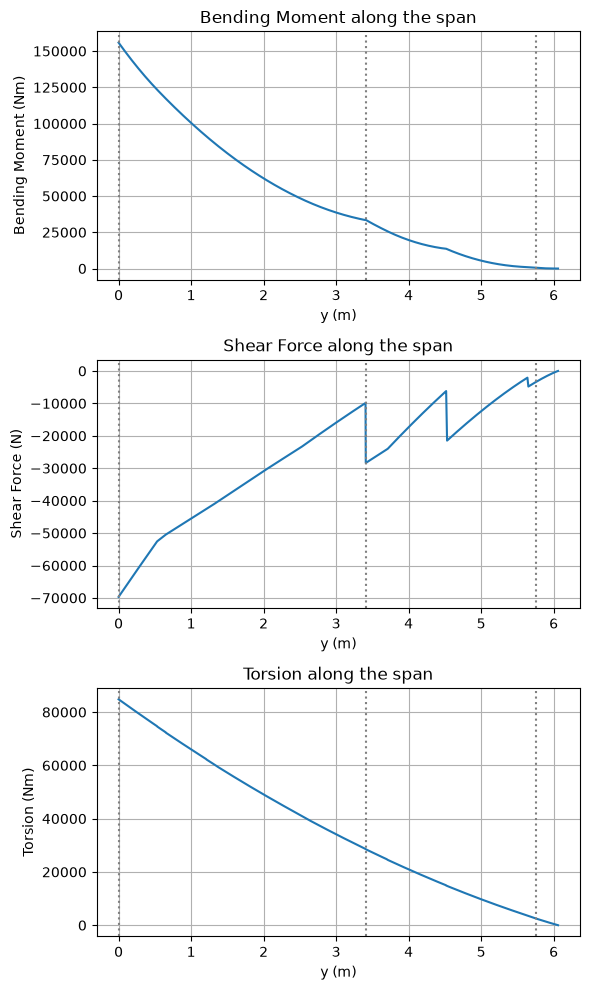

In [27]:
LOAD_PLOTS = [('Bending_Moment', 'Bending Moment (Nm)'),
              ('Shear_Force',    'Shear Force (N)'),
              ('Torsion',        'Torsion (Nm)')]

fig, axs = plt.subplots(3, 1, figsize=(6, 10))
for ax, (col, label) in zip(axs, LOAD_PLOTS):
    ax.plot(N6['y'], N6[col])
    for st in STATIONS:
        ax.axvline(N6.loc[N6['Section'] == st.section, 'y'].iloc[0], ls=':', c='gray')
    ax.set(xlabel='y (m)', ylabel=label, title=f'{label.split(" (")[0]} along the span')
    ax.grid()
plt.tight_layout()
plt.show()

# 3. Airfoil & wingbox geometry
NACA 4-digit thickness and camber lines (Abbott & von Doenhoff). Spar heights are measured
**vertically** at the spar stations on the upper/lower surfaces.

In [12]:
def naca4(x, t, m, p, c=1.0):
    # x: normalised chord positions 0..1. Returns (xu, yu, xl, yl) scaled by chord c.
    x = np.asarray(x, dtype=float)
    yt = 5 * t * (0.2969 * np.sqrt(x) - 0.1260 * x - 0.3516 * x**2 + 0.2843 * x**3 - 0.1015 * x**4)
    fore = x <= p
    yc = np.where(fore, m / p**2 * (2 * p * x - x**2),
                        m / (1 - p)**2 * ((1 - 2 * p) + 2 * p * x - x**2))
    dyc_dx = np.where(fore, 2 * m / p**2 * (p - x), 2 * m / (1 - p)**2 * (p - x))
    theta = np.arctan(dyc_dx)
    return ((x - yt * np.sin(theta)) * c, (yc + yt * np.cos(theta)) * c,
            (x + yt * np.sin(theta)) * c, (yc - yt * np.cos(theta)) * c)


def _surface_y(xq, xs, ys):
    # np.interp needs increasing xs; the upper surface folds back slightly at the nose
    i0 = np.argmin(xs)
    return np.interp(xq, xs[i0:], ys[i0:])


class Airfoil:
    def __init__(self, chord, t, m, p, n=500):
        self.chord = chord
        x = 0.5 * (1 - np.cos(np.linspace(0, np.pi, n)))   # cosine spacing, dense at LE/TE
        self.xu, self.yu, self.xl, self.yl = naca4(x, t, m, p, chord)

    def y_upper(self, x):
        return _surface_y(x, self.xu, self.yu)

    def y_lower(self, x):
        return _surface_y(x, self.xl, self.yl)

    def height(self, x):
        return self.y_upper(x) - self.y_lower(x)


@dataclass(frozen=True)
class WingboxGeometry:
    chord: float
    x_f: float       # m, front spar
    x_r: float       # m, rear spar
    hf: float        # m, front spar height
    hr: float        # m, rear spar height

    @property
    def h_avg(self):
        return 0.5 * (self.hf + self.hr)

    @property
    def width(self):
        return self.x_r - self.x_f

    @property
    def A_box(self):     # enclosed area used for torsion (Bredt-Batho)
        return self.h_avg * self.width


def wingbox_geometry(chord):
    af = Airfoil(chord, **AIRFOIL)
    x_f, x_r = FRONT_SPAR * chord, REAR_SPAR * chord
    return WingboxGeometry(chord, x_f, x_r, af.height(x_f), af.height(x_r))


GEOM = {st.name: wingbox_geometry(st.chord) for st in STATIONS}

pd.DataFrame({name: {'chord (m)': g.chord, 'hf (m)': g.hf, 'hr (m)': g.hr, 'h_avg (m)': g.h_avg,
                     'box width (m)': g.width, 'A_box (m2)': g.A_box}
              for name, g in GEOM.items()}).T

,chord (m),hf (m),hr (m),h_avg (m),box width (m),A_box (m2)
Root,2.570,0.461,0.245,0.353,1.285,0.454
Hardpoint,1.950,0.350,0.186,0.268,0.975,0.261
Tip,1.160,0.208,0.111,0.159,0.580,0.092


# 4. Design loads
The datasheet gives **limit** loads (already include the load factor *n*).
Ultimate load = `FACTOR_OF_SAFETY` × limit; magnitudes are used (signs are handled in the stress check:
positive bending puts the upper cover in compression).

> ⚠ The datasheet `Chord` column (shown below) does not match the design chords in `STATIONS`.
> Check which one is correct for this aircraft before submitting.

In [13]:
@dataclass(frozen=True)
class Loads:
    M: float    # Nm
    V: float    # N
    T: float    # Nm

    def __mul__(self, k):
        return Loads(self.M * k, self.V * k, self.T * k)


def station_row(data, section):
    rows = data.loc[data['Section'] == section]
    if rows.empty:
        raise KeyError(f'Section {section} not found in datasheet')
    return rows.iloc[0]


def limit_loads(data, section):
    row = station_row(data, section)
    return Loads(abs(row['Bending_Moment']), abs(row['Shear_Force']), abs(row['Torsion']))


LIMIT = {st.name: limit_loads(N6, st.section) for st in STATIONS}
ULTIMATE = {name: ld * FACTOR_OF_SAFETY for name, ld in LIMIT.items()}

pd.DataFrame({st.name: {'y (m)': station_row(N6, st.section)['y'],
                        'datasheet chord (m)': station_row(N6, st.section)['Chord'],
                        'design chord (m)': st.chord,
                        'M limit (Nm)': LIMIT[st.name].M, 'V limit (N)': LIMIT[st.name].V,
                        'T limit (Nm)': LIMIT[st.name].T,
                        'M ult (Nm)': ULTIMATE[st.name].M, 'V ult (N)': ULTIMATE[st.name].V,
                        'T ult (Nm)': ULTIMATE[st.name].T}
              for st in STATIONS})

,Root,Hardpoint,Tip
y (m),0.000,3.405,5.757
datasheet chord (m),1.500,1.050,0.740
design chord (m),2.570,1.950,1.160
M limit (Nm),155834.661,33631.202,477.196
V limit (N),69673.150,9874.427,3373.213
T limit (Nm),84804.535,28618.492,2491.161
M ult (Nm),233751.991,50446.802,715.794
V ult (N),104509.725,14811.640,5059.820
T ult (Nm),127206.802,42927.739,3736.742


# 5. Initial sizing

| Item | Formula |
|---|---|
| Cover allowable (panel efficiency) | $f_b = 138\cdot1.02\,\sqrt{N/L}$ [MPa], $N = M/(h_{avg}\,w)$ [MN/m], $L$ = rib pitch |
| Effective cover thickness | $t_{eff} = M/(h_{avg}\,w\,f_b)$, $\;t_{skin} = 0.65\,t_{eff} \ge$ min gauge |
| Torsion shear flow | $q_T = T/(2A)$ |
| Vertical-shear split (by $h^2$) | $q_{V,i} = V\,h_i^2 / [(h_f^2+h_r^2)\,h_{avg}]$ |
| Spar web | $t_{w,i} = (q_{V,i}+q_T)/\tau_{allow}$ (torsion added on both webs → conservative) |
| Spar cap flanges | $t_{flange,w} = 2\,t_{skin}$, $\;t_{flange,h} = t_{fw}+t_{rw}$ |
| Stringer | $t_{str}=t_{skin},\; e = 2\,t_{skin},\; h = 5\,t_{skin}$ |
| Rib web | $t_{rib} = V/(2\,h_{avg}\,\tau_{allow})$ |

In [14]:
def cover_allowable(M, h_avg, width, L):
    N = M / (h_avg * width) / 1e6                         # MN/m
    return PANEL_EFF_COEFF * np.sqrt(N / L) * MPA         # Pa


def size_skin(M, h_avg, width, fb):
    t_eff = M / (h_avg * width * fb)
    return t_eff, max(SKIN_SHARE * t_eff, MIN_GAUGE)


def spar_shear_flows(V, T, g):
    # Shared by sizing (section 5) and checking (section 8)
    q_T = T / (2 * g.A_box)
    denom = (g.hf**2 + g.hr**2) * g.h_avg
    q_f = abs(V) * g.hf**2 / denom + abs(q_T)
    q_r = abs(V) * g.hr**2 / denom + abs(q_T)
    return q_f, q_r


def size_stringer(t_skin):
    return (t_skin, 2 * t_skin, 5 * t_skin)    # (t, e, h)


def size_rib_web(V, h_avg, tau_allow):
    return abs(V) / (2 * h_avg * tau_allow)


@dataclass(frozen=True)
class Design:
    t_skin: float       # m
    t_fw: float         # m, front spar web
    t_rw: float         # m, rear spar web
    stringer: tuple     # m, (t, e, h)

    @classmethod
    def from_mm(cls, t_skin, t_web, stringer):
        return cls(t_skin * MM, t_web[0] * MM, t_web[1] * MM, tuple(v * MM for v in stringer))

    @property
    def A_str(self):
        t, e, h = self.stringer
        return (2 * e + h) * t


def initial_sizing(g, loads):
    fb = cover_allowable(loads.M, g.h_avg, g.width, RIB_PITCH)
    t_eff, t_skin = size_skin(loads.M, g.h_avg, g.width, fb)
    q_f, q_r = spar_shear_flows(loads.V, loads.T, g)
    tau = MAT['spar'].tau_y
    design = Design(t_skin, q_f / tau, q_r / tau, size_stringer(t_skin))
    extra = dict(fb=fb, t_eff=t_eff,
                 t_flange_w=2 * t_skin, t_flange_h=design.t_fw + design.t_rw,
                 t_rib=size_rib_web(loads.V, g.h_avg, MAT['rib'].tau_y))
    return design, extra


SIZING = {st.name: initial_sizing(GEOM[st.name], ULTIMATE[st.name]) for st in STATIONS}
AUTO_DESIGN = {name: d for name, (d, _) in SIZING.items()}


def sizing_table(sizing):
    rows = {}
    for name, (d, x) in sizing.items():
        rows[name] = {
            'Cover allowable fb (MPa)': x['fb'] / MPA,
            'Skin t_eff (mm)':          x['t_eff'] / MM,
            'Skin t (mm)':              d.t_skin / MM,
            'Front spar web t (mm)':    d.t_fw / MM,
            'Rear spar web t (mm)':     d.t_rw / MM,
            'Spar flange t, w (mm)':    x['t_flange_w'] / MM,
            'Spar flange t, h (mm)':    x['t_flange_h'] / MM,
            'Rib web t (mm)':           x['t_rib'] / MM,
            'Stringer t (mm)':          d.stringer[0] / MM,
            'Stringer e (mm)':          d.stringer[1] / MM,
            'Stringer h (mm)':          d.stringer[2] / MM,
        }
    return pd.DataFrame(rows)


sizing_table(SIZING)

,Root,Hardpoint,Tip
Cover allowable fb (MPa),184.492,112.958,22.619
Skin t_eff (mm),2.793,1.710,0.342
Skin t (mm),1.816,1.112,1.000
Front spar web t (mm),1.475,0.498,0.179
Rear spar web t (mm),0.818,0.375,0.108
"Spar flange t, w (mm)",3.631,2.223,2.000
"Spar flange t, h (mm)",2.292,0.874,0.287
Rib web t (mm),0.589,0.110,0.063
Stringer t (mm),1.816,1.112,1.000
Stringer e (mm),3.631,2.223,2.000


# 6. Airfoil structure
Same chords, spar positions and stringer layout as used in the analysis.

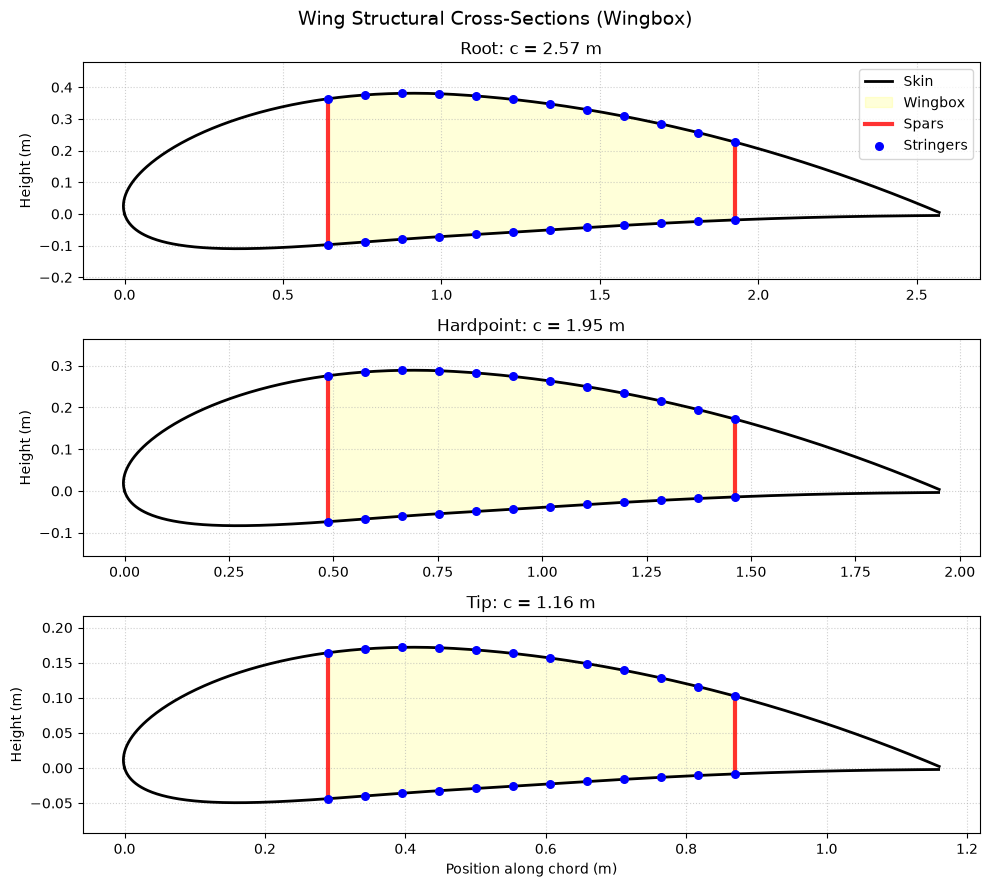

In [15]:
def boom_x(g):
    return np.linspace(g.x_f, g.x_r, N_BOOMS_PER_SURFACE)


fig, axs = plt.subplots(len(STATIONS), 1, figsize=(10, 3 * len(STATIONS)))
fig.suptitle('Wing Structural Cross-Sections (Wingbox)', fontsize=14)

for ax, st in zip(axs, STATIONS):
    g, af = GEOM[st.name], Airfoil(st.chord, **AIRFOIL)
    ax.plot(af.xu, af.yu, 'k-', lw=2, label='Skin')
    ax.plot(af.xl, af.yl, 'k-', lw=2)

    x_box = np.linspace(g.x_f, g.x_r, 100)
    ax.fill_between(x_box, af.y_lower(x_box), af.y_upper(x_box), color='yellow', alpha=0.15, label='Wingbox')

    for x, lbl in [(g.x_f, 'Spars'), (g.x_r, None)]:
        ax.plot([x, x], [af.y_lower(x), af.y_upper(x)], 'r-', lw=3, alpha=0.8, label=lbl)

    xb = boom_x(g)
    ax.scatter(xb, af.y_upper(xb), c='blue', s=30, zorder=5, label='Stringers')
    ax.scatter(xb, af.y_lower(xb), c='blue', s=30, zorder=5)

    ax.set_title(f'{st.name}: c = {st.chord} m')
    ax.set_ylabel('Height (m)')
    ax.axis('equal')
    ax.grid(True, linestyle=':', alpha=0.6)

axs[0].legend(loc='upper right')
axs[-1].set_xlabel('Position along chord (m)')
plt.tight_layout()
plt.show()

# 7. Kunjungan Lab (reference data)

In [16]:
LAB_VISIT = pd.DataFrame([
    ('Ribs',     'Flange thickness',            2.0),
    ('Ribs',     'Web thickness',               2.0),
    ('Ribs',     'Rivet spacing',              19.0),
    ('Ribs',     'Rib spacing',               500.0),
    ('Skin',     'Skin thickness',              1.4),
    ('Spar',     'Front & rear web thickness',  2.3),
    ('Spar',     'Flange thickness',            3.9),
    ('Stringer', 'Thickness',                   2.7),
    ('Stringer', 'h_stringer',                 39.3),
    ('Stringer', 'Spacing',                    89.5),
], columns=['Component', 'Item', 'Value (mm)'])
LAB_VISIT

,Component,Item,Value (mm)
0,Ribs,Flange thickness,2.000
1,Ribs,Web thickness,2.000
2,Ribs,Rivet spacing,19.000
3,Ribs,Rib spacing,500.000
4,Skin,Skin thickness,1.400
5,Spar,Front & rear web thickness,2.300
6,Spar,Flange thickness,3.900
7,Stringer,Thickness,2.700
8,Stringer,h_stringer,39.300
9,Stringer,Spacing,89.500


# 8. Stress & stability check

**Idealisation:** stringers as booms; skin panels, spar webs and booms all carry bending.
The neutral axis is the **centroid** of that section (the cambered box is not symmetric about the chord line).

| Check | Formula | Applied to |
|---|---|---|
| Bending | $\sigma = -M\,(y-\bar y)/I_{xx}$ | all booms (upper = compression for $M>0$) |
| Shear | $\tau_i = q_i / t_{w,i}$ (same $q$ as sizing) | spar webs |
| Yield | $\|\sigma\| \le \sigma_y$; webs: $\sqrt3\,\tau \le \sigma_y$ | stringers, upper/lower skin, webs |
| Skin buckling | $\sigma_{cr} = \dfrac{k_c\pi^2E}{12(1-\nu^2)}\left(\dfrac{t}{b}\right)^2$, $b$ = stringer pitch | compressed panels only |
| Crippling | $\sigma_{cc} = \min\!\left[C\,E\,(t/e)^{0.85},\ \sigma_y\right]$ | compressed stringers only |
| Column | Euler $\sigma_e = \pi^2E/(KL/r)^2$; Johnson $\sigma_y\!\left(1-\dfrac{\sigma_y}{4\sigma_e}\right)$ when $\sigma_e > \sigma_y/2$ | compressed stringers only |
| Web shear buckling | $\tau_{cr} = \dfrac{k_s\pi^2E}{12(1-\nu^2)}\left(\dfrac{t}{b}\right)^2$, $k_s = 5.35 + 4(b/a)^2$, $b=\min(h,L)$ | spar webs |

Margin of safety: $MoS = \text{allowable}/\text{applied} - 1$, evaluated at **ultimate** load (conservative against yield).

In [17]:
def build_section(g, design):
    # Returns (booms DataFrame, y_centroid, Ixx about centroid)
    af = Airfoil(g.chord, **AIRFOIL)
    xb = boom_x(g)
    n = len(xb)
    booms = pd.DataFrame({
        'ID':      [f'U{i + 1}' for i in range(n)] + [f'L{i + 1}' for i in range(n)],
        'surface': ['upper'] * n + ['lower'] * n,
        'x':       np.concatenate([xb, xb]),
        'y':       np.concatenate([af.y_upper(xb), af.y_lower(xb)]),
        'A':       design.A_str,
    })

    # skin panels between adjacent booms: (t*L, y1, y2)
    panels = []
    for _, s in booms.groupby('surface'):
        x, y = s['x'].to_numpy(), s['y'].to_numpy()
        L = np.hypot(np.diff(x), np.diff(y))
        panels += list(zip(design.t_skin * L, y[:-1], y[1:]))
    # spar webs: (t*h, y_bottom, y_top)
    webs = [(t * (af.y_upper(x) - af.y_lower(x)), af.y_lower(x), af.y_upper(x))
            for t, x in [(design.t_fw, g.x_f), (design.t_rw, g.x_r)]]

    # centroid
    A_tot = booms['A'].sum() + sum(a for a, *_ in panels + webs)
    Ay = (booms['A'] * booms['y']).sum() + sum(a * (y1 + y2) / 2 for a, y1, y2 in panels + webs)
    y_c = Ay / A_tot

    # second moment of area about the centroid (straight thin panel: A/3 (a^2 + ab + b^2))
    Ixx = (booms['A'] * (booms['y'] - y_c)**2).sum()
    for a, y1, y2 in panels + webs:
        d1, d2 = y1 - y_c, y2 - y_c
        Ixx += a / 3 * (d1**2 + d1 * d2 + d2**2)
    return booms, y_c, Ixx


def calc_mos(allowable, applied):
    applied = abs(applied)
    return np.inf if applied < 1e-9 else allowable / applied - 1


def plate_buckling(k, mat, t, b):
    return k * np.pi**2 * mat.E / (12 * (1 - mat.nu**2)) * (t / b)**2


def johnson_euler(mat, L, r, K=1.0):
    sigma_e = np.pi**2 * mat.E / (K * L / r)**2
    if sigma_e <= mat.sigma_y / 2:
        return sigma_e
    return mat.sigma_y * (1 - mat.sigma_y / (4 * sigma_e))


def stringer_allowables(design):
    mat = MAT['stringer']
    t, e, h = design.stringer
    I = t * h**3 / 12 + 2 * e * t * (h / 2)**2
    r = np.sqrt(I / design.A_str)
    crippling = min(C_CRIP * mat.E * (t / e)**0.85, mat.sigma_y)
    column = johnson_euler(mat, RIB_PITCH, r, K_COL)
    return crippling, column


def web_shear_buckling(t, h):
    b, a = min(h, RIB_PITCH), max(h, RIB_PITCH)
    ks = 5.35 + 4.0 * (b / a)**2
    return plate_buckling(ks, MAT['spar'], t, b)


def check_section(g, loads, design):
    booms, y_c, Ixx = build_section(g, design)
    booms['sigma'] = -loads.M * (booms['y'] - y_c) / Ixx
    pitch = g.width / (N_BOOMS_PER_SURFACE - 1)

    sig_skin_cr = plate_buckling(KC_SKIN, MAT['upper_skin'], design.t_skin, pitch)
    sig_crip, sig_col = stringer_allowables(design)
    q_f, q_r = spar_shear_flows(loads.V, loads.T, g)
    webs = [('Front spar', q_f / design.t_fw, design.t_fw, g.hf),
            ('Rear spar',  q_r / design.t_rw, design.t_rw, g.hr)]

    rows = []

    def add(check, comp, applied, allowable):
        rows.append(dict(Check=check, Component=comp, Applied_MPa=abs(applied) / MPA,
                         Allowable_MPa=allowable / MPA, MoS=calc_mos(allowable, applied)))

    for b in booms.itertuples():
        skin_mat = MAT['upper_skin'] if b.surface == 'upper' else MAT['lower_skin']
        add('Yield - stringer', b.ID, b.sigma, MAT['stringer'].sigma_y)
        add('Yield - skin', b.ID, b.sigma, skin_mat.sigma_y)
        if b.sigma < 0:                        # stability checks only where compressed
            add('Skin buckling', b.ID, b.sigma, sig_skin_cr)
            add('Crippling', b.ID, b.sigma, sig_crip)
            add('Column buckling', b.ID, b.sigma, sig_col)
    for name, tau, t, h in webs:
        add('Yield - spar web (VM)', name, np.sqrt(3) * tau, MAT['spar'].sigma_y)
        add('Web shear buckling', name, tau, web_shear_buckling(t, h))

    results = pd.DataFrame(rows)
    results['Status'] = np.where(results['MoS'] >= 0, 'SAFE', 'FAIL')
    return dict(geom=g, loads=loads, design=design, booms=booms, y_c=y_c, Ixx=Ixx,
                shear=pd.DataFrame([(n, tau * t, t / MM, tau / MPA) for n, tau, t, _ in webs],
                                   columns=['Web', 'q (N/m)', 't (mm)', 'tau (MPa)']),
                results=results)


def governing(results):
    # lowest MoS for each check
    idx = results.groupby('Check', sort=False)['MoS'].idxmin()
    return results.loc[idx].reset_index(drop=True)


def report(name, res, show_all=False):
    d = res['design']
    print(f"\n{'#' * 78}\n {name}\n{'#' * 78}")
    print(f"skin t = {d.t_skin / MM:.2f} mm | webs (front, rear) = ({d.t_fw / MM:.2f}, {d.t_rw / MM:.2f}) mm | "
          f"stringer (t, e, h) = ({', '.join(f'{v / MM:.2f}' for v in d.stringer)}) mm")
    print(f"y_centroid = {res['y_c'] * 1000:.1f} mm | Ixx = {res['Ixx']:.3e} m^4")
    print('\nSpar web shear:')
    print(res['shear'].to_string(index=False))
    print('\nGoverning margin per check:')
    print(governing(res['results']).to_string(index=False))
    if show_all:
        print(res['results'].to_string(index=False))


def plot_section(name, res):
    g, booms = res['geom'], res['booms']
    af = Airfoil(g.chord, **AIRFOIL)
    yld = res['results'].query("Check == 'Yield - stringer'").set_index('Component')['MoS']

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(af.xu, af.yu, 'k-', alpha=0.8, label='Skin')
    ax.plot(af.xl, af.yl, 'k-', alpha=0.8)
    for x, lbl in [(g.x_f, 'Spars'), (g.x_r, None)]:
        ax.plot([x, x], [af.y_lower(x), af.y_upper(x)], 'r-', lw=3, zorder=2, label=lbl)
    ax.axhline(res['y_c'], color='gray', ls='--', lw=1, label='Neutral axis')

    for surf, color in [('upper', 'blue'), ('lower', 'green')]:
        s = booms[booms['surface'] == surf]
        ax.scatter(s['x'], s['y'], c=color, s=60, zorder=3, label=f'Stringer {surf}')
        off = 0.03 if surf == 'upper' else -0.05
        for b in s.itertuples():
            mos = yld[b.ID]
            ax.text(b.x, b.y + off, f'{b.ID}\n{mos:.2f}', ha='center', fontsize=7,
                    color='blue' if mos >= 0 else 'red', fontweight='bold')

    ax.set_title(f'{name}: stringer yield MoS', fontsize=13)
    ax.set_xlabel('Chord position (m)')
    ax.set_ylabel('Height (m)')
    ax.axis('equal')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def run_all(designs, tag):
    out = {}
    for st in STATIONS:
        res = check_section(GEOM[st.name], ULTIMATE[st.name], designs[st.name])
        report(f'{st.name.upper()} ({tag})', res)
        plot_section(f'{st.name} ({tag})', res)
        out[st.name] = res
    return out


def mos_summary(all_res):
    return pd.DataFrame({name: governing(r['results']).set_index('Check')['MoS']
                         for name, r in all_res.items()})

## 8.1 Auto-sized design (from section 5)


##############################################################################
 ROOT (auto-sized)
##############################################################################
skin t = 1.82 mm | webs (front, rear) = (1.47, 0.82) mm | stringer (t, e, h) = (1.82, 3.63, 9.08) mm
y_centroid = 138.8 mm | Ixx = 2.256e-04 m^4

Spar web shear:
       Web    q (N/m)  t (mm)  tau (MPa)
Front spar 370900.629   1.475    251.500
 Rear spar 205651.417   0.818    251.500

Governing margin per check:
                Check  Component  Applied_MPa  Allowable_MPa    MoS Status
     Yield - stringer         U3      250.667        421.000  0.680   SAFE
         Yield - skin         U3      250.667        345.000  0.376   SAFE
        Skin buckling         U3      250.667         63.953 -0.745   FAIL
            Crippling         U3      250.667        421.000  0.680   SAFE
      Column buckling         U3      250.667        102.012 -0.593   FAIL
Yield - spar web (VM) Front spar      435.611        503.0

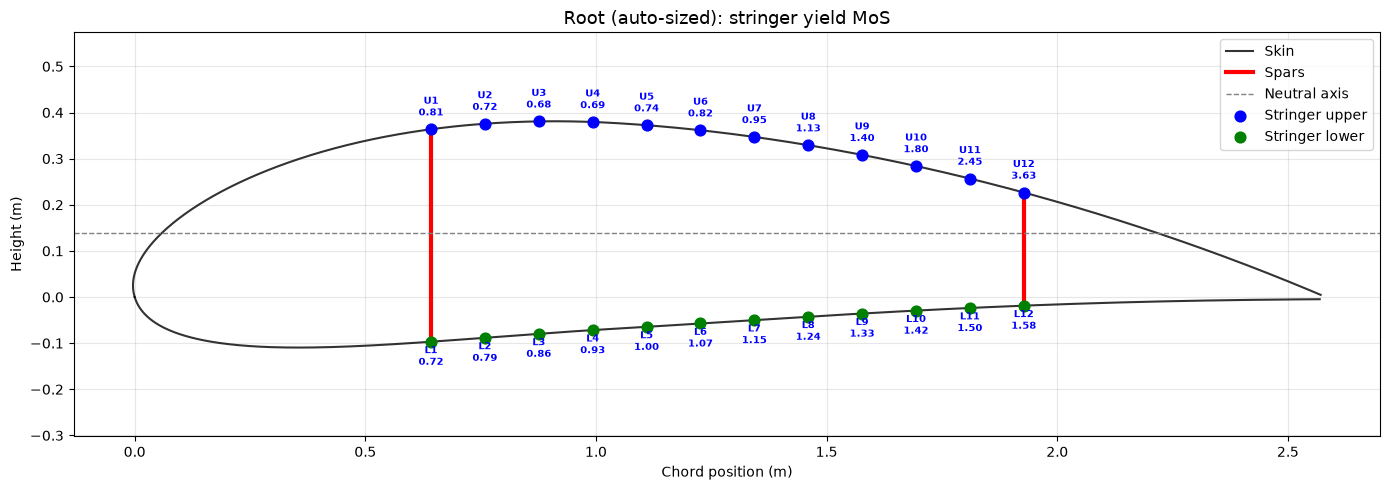


##############################################################################
 HARDPOINT (auto-sized)
##############################################################################
skin t = 1.11 mm | webs (front, rear) = (0.50, 0.38) mm | stringer (t, e, h) = (1.11, 2.22, 5.56) mm
y_centroid = 105.8 mm | Ixx = 5.738e-05 m^4

Spar web shear:
       Web    q (N/m)  t (mm)  tau (MPa)
Front spar 125285.355   0.498    251.500
 Rear spar  94419.070   0.375    251.500

Governing margin per check:
                Check  Component  Applied_MPa  Allowable_MPa    MoS Status
     Yield - stringer         U3      160.999        421.000  1.615   SAFE
         Yield - skin         U3      160.999        345.000  1.143   SAFE
        Skin buckling         U3      160.999         41.642 -0.741   FAIL
            Crippling         U3      160.999        421.000  1.615   SAFE
      Column buckling         U3      160.999         38.241 -0.762   FAIL
Yield - spar web (VM) Front spar      435.611        

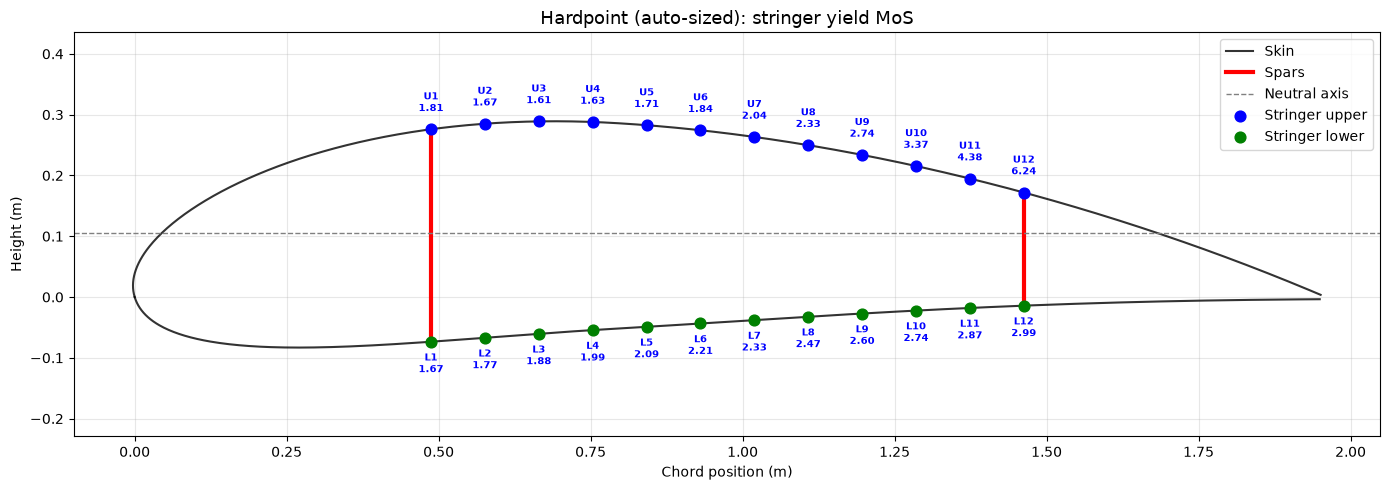


##############################################################################
 TIP (auto-sized)
##############################################################################
skin t = 1.00 mm | webs (front, rear) = (0.18, 0.11) mm | stringer (t, e, h) = (1.00, 2.00, 5.00) mm
y_centroid = 63.3 mm | Ixx = 1.121e-05 m^4

Spar web shear:
       Web   q (N/m)  t (mm)  tau (MPa)
Front spar 44962.329   0.179    251.500
 Rear spar 27237.058   0.108    251.500

Governing margin per check:
                Check  Component  Applied_MPa  Allowable_MPa    MoS Status
     Yield - stringer         U3        6.931        421.000 59.740   SAFE
         Yield - skin         U3        6.931        345.000 48.775   SAFE
        Skin buckling         U3        6.931         95.214 12.737   SAFE
            Crippling         U3        6.931        421.000 59.740   SAFE
      Column buckling         U3        6.931         30.942  3.464   SAFE
Yield - spar web (VM) Front spar      435.611        503.000  0

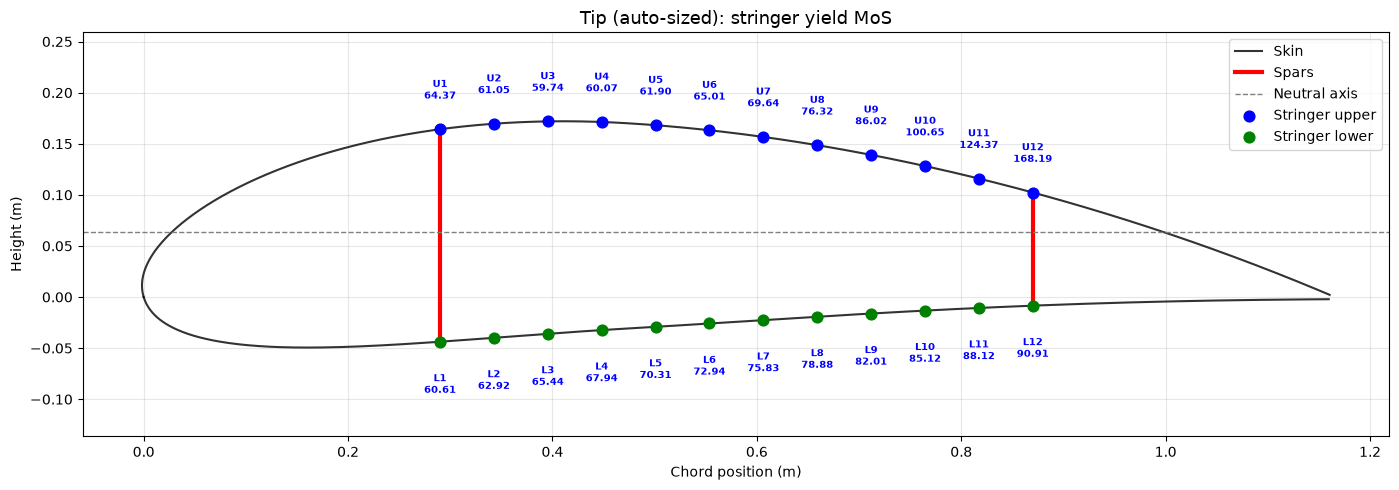

,Root,Hardpoint,Tip
Check,,,
Yield - stringer,0.680,1.615,59.740
Yield - skin,0.376,1.143,48.775
Skin buckling,-0.745,-0.741,12.737
Crippling,0.680,1.615,59.740
Column buckling,-0.593,-0.762,3.464
Yield - spar web (VM),0.155,0.155,0.155
Web shear buckling,-0.977,-0.994,-0.999


In [18]:
RES_AUTO = run_all(AUTO_DESIGN, 'auto-sized')
mos_summary(RES_AUTO)

# 9. Final design (overrides → SAFE)
Edit `FINAL_DESIGN_MM` in the configuration cell.


##############################################################################
 ROOT (final)
##############################################################################
skin t = 2.50 mm | webs (front, rear) = (10.00, 10.00) mm | stringer (t, e, h) = (2.50, 30.00, 45.00) mm
y_centroid = 133.9 mm | Ixx = 5.962e-04 m^4

Spar web shear:
       Web    q (N/m)  t (mm)  tau (MPa)
Front spar 370900.629  10.000     37.090
 Rear spar 205651.417  10.000     20.565

Governing margin per check:
                Check  Component  Applied_MPa  Allowable_MPa    MoS Status
     Yield - stringer         U3       96.776        421.000  3.350   SAFE
         Yield - skin         U3       96.776        345.000  2.565   SAFE
        Skin buckling         U3       96.776        121.236  0.253   SAFE
            Crippling         U3       96.776        421.000  3.350   SAFE
      Column buckling         U3       96.776        405.416  3.189   SAFE
Yield - spar web (VM) Front spar       64.242        503.00

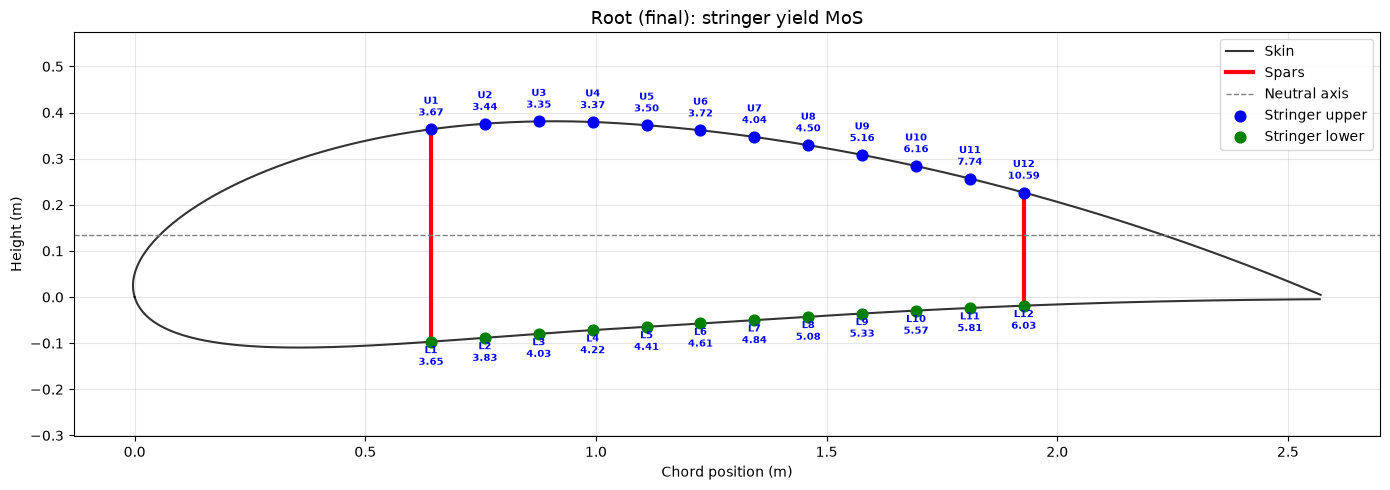


##############################################################################
 HARDPOINT (final)
##############################################################################
skin t = 2.50 mm | webs (front, rear) = (7.00, 7.00) mm | stringer (t, e, h) = (2.50, 25.00, 25.00) mm
y_centroid = 102.5 mm | Ixx = 2.416e-04 m^4

Spar web shear:
       Web    q (N/m)  t (mm)  tau (MPa)
Front spar 125285.355   7.000     17.898
 Rear spar  94419.070   7.000     13.488

Governing margin per check:
                Check  Component  Applied_MPa  Allowable_MPa    MoS Status
     Yield - stringer         U3       38.921        421.000  9.817   SAFE
         Yield - skin         U3       38.921        345.000  7.864   SAFE
        Skin buckling         U3       38.921        210.585  4.411   SAFE
            Crippling         U3       38.921        421.000  9.817   SAFE
      Column buckling         U3       38.921        374.628  8.625   SAFE
Yield - spar web (VM) Front spar       31.000        503

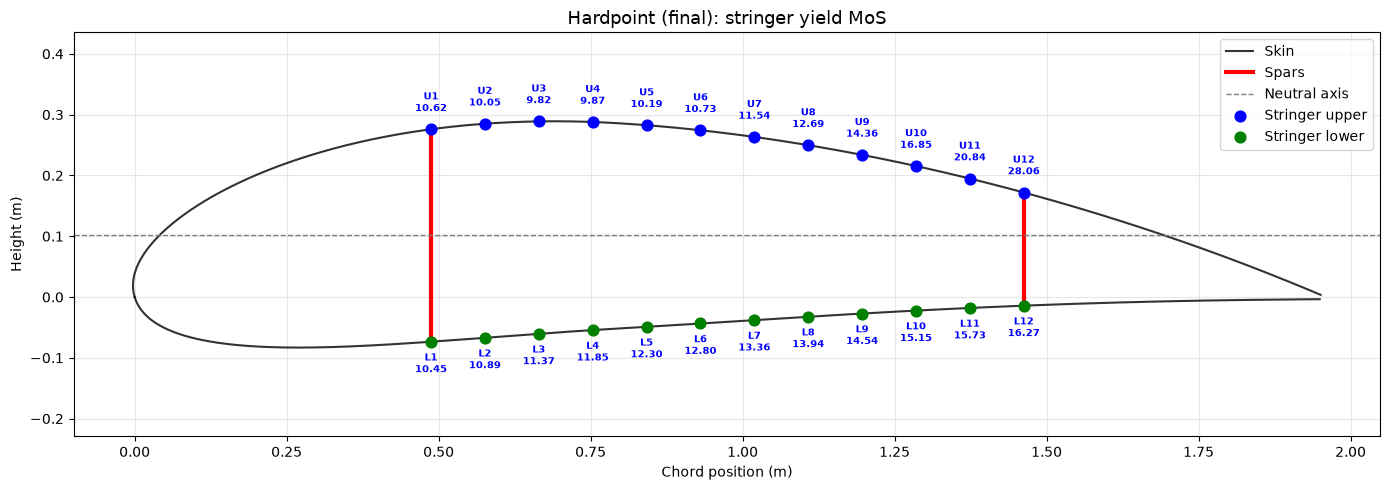


##############################################################################
 TIP (final)
##############################################################################
skin t = 2.50 mm | webs (front, rear) = (5.00, 5.00) mm | stringer (t, e, h) = (1.50, 20.00, 25.00) mm
y_centroid = 61.4 mm | Ixx = 4.640e-05 m^4

Spar web shear:
       Web   q (N/m)  t (mm)  tau (MPa)
Front spar 44962.329   5.000      8.992
 Rear spar 27237.058   5.000      5.447

Governing margin per check:
                Check  Component  Applied_MPa  Allowable_MPa     MoS Status
     Yield - stringer         U3        1.704        421.000 246.126   SAFE
         Yield - skin         U3        1.704        345.000 201.514   SAFE
        Skin buckling         U3        1.704        595.087 348.314   SAFE
            Crippling         U3        1.704        421.000 246.126   SAFE
      Column buckling         U3        1.704        372.496 217.654   SAFE
Yield - spar web (VM) Front spar       15.575        503.000

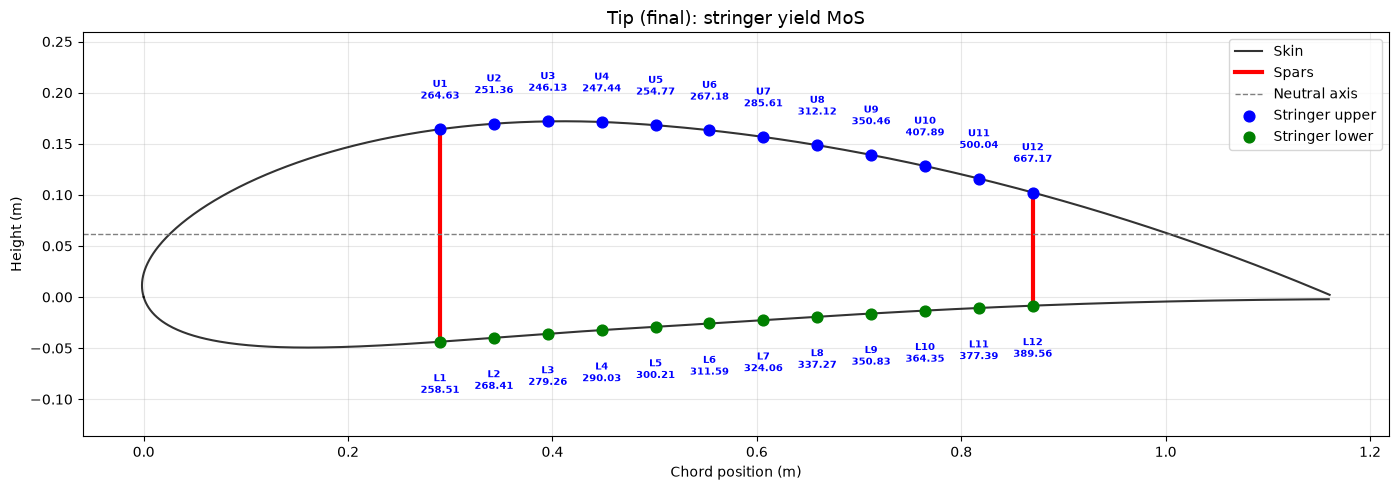

,Root,Hardpoint,Tip
Check,,,
Yield - stringer,3.350,9.817,246.126
Yield - skin,2.565,7.864,201.514
Skin buckling,0.253,4.411,348.314
Crippling,3.350,9.817,246.126
Column buckling,3.189,8.625,217.654
Yield - spar web (VM),6.830,15.226,31.294
Web shear buckling,12.970,15.703,29.948


In [19]:
FINAL_DESIGN = {name: Design.from_mm(**v) for name, v in FINAL_DESIGN_MM.items()}
RES_FINAL = run_all(FINAL_DESIGN, 'final')
mos_summary(RES_FINAL)

In [20]:
# governing MoS per check; negative = FAIL
summary = pd.concat({'auto-sized': mos_summary(RES_AUTO), 'final': mos_summary(RES_FINAL)}, axis=1)
summary['final all SAFE'] = (summary['final'] >= 0).all(axis=1)
summary

auto-sized                   final                    \
                            Root Hardpoint    Tip   Root Hardpoint     Tip   
Check                                                                        
Yield - stringer           0.680     1.615 59.740  3.350     9.817 246.126   
Yield - skin               0.376     1.143 48.775  2.565     7.864 201.514   
Skin buckling             -0.745    -0.741 12.737  0.253     4.411 348.314   
Crippling                  0.680     1.615 59.740  3.350     9.817 246.126   
Column buckling           -0.593    -0.762  3.464  3.189     8.625 217.654   
Yield - spar web (VM)      0.155     0.155  0.155  6.830    15.226  31.294   
Web shear buckling        -0.977    -0.994 -0.999 12.970    15.703  29.948   

                      final all SAFE  
                                      
Check                                 
Yield - stringer                True  
Yield - skin                    True  
Skin buckling                   True  
Crippling                       True  
Column buckling                 True  
Yield - spar web (VM)           True  
Web shear buckling              True

# 10. Wing weight estimate
Semi-empirical area factors (constants below). Thicknesses are the averages of the **final design**
over the three stations, so this cell updates automatically when the design changes.

In [21]:
SKIN_AREA_FACTOR = 2.05      # wetted (upper + lower) skin area / planform area
SPAR_AREA_FACTOR = 0.24      # (front + rear) web area / planform area  (~2 x 0.12 c)
RIB_AREA_FACTOR = 0.04       # rib area / c^2
RIB_THICKNESS = 2.0 * MM     # m (lab visit: rib web 2 mm)
N_STRINGERS = 2 * (N_BOOMS_PER_SURFACE - 2)   # spanwise stringers, excluding the booms at spar caps


def wing_weight(semi_span, c_root, c_tip, designs):
    d = list(designs.values())
    t_skin = np.mean([x.t_skin for x in d])
    t_spar = np.mean([(x.t_fw + x.t_rw) / 2 for x in d])
    A_str = np.mean([x.A_str for x in d])
    n_ribs = int(round(semi_span / RIB_PITCH)) + 1

    S_half = semi_span * (c_root + c_tip) / 2
    y_rib = np.linspace(0, semi_span, n_ribs)
    c_rib = c_root - (c_root - c_tip) * y_rib / semi_span

    mass = {
        'Skin':                SKIN_AREA_FACTOR * S_half * t_skin * MAT['upper_skin'].rho,
        'Spars':               SPAR_AREA_FACTOR * S_half * t_spar * MAT['spar'].rho,
        'Stringers':           N_STRINGERS * A_str * semi_span * MAT['stringer'].rho,
        f'Ribs ({n_ribs} pcs)': (RIB_AREA_FACTOR * c_rib**2 * RIB_THICKNESS).sum() * MAT['rib'].rho,
    }
    half = sum(mass.values())
    df = pd.DataFrame({'Mass (kg)': mass})
    df['Percentage (%)'] = df['Mass (kg)'] / half * 100
    df.loc['TOTAL HALF WING'] = [half, 100.0]
    df.loc['TOTAL FULL WING'] = [2 * half, np.nan]
    inputs = {'avg t_skin (mm)': t_skin / MM, 'avg t_spar (mm)': t_spar / MM, 'avg A_str (mm2)': A_str / MM**2}
    return df, inputs


df_weight, weight_inputs = wing_weight(SEMI_SPAN, STATIONS[0].chord, STATIONS[-1].chord, FINAL_DESIGN)
print(f'span = {2 * SEMI_SPAN:.2f} m |', ' | '.join(f'{k} = {v:.2f}' for k, v in weight_inputs.items()))
df_weight

span = 12.12 m | avg t_skin (mm) = 2.50 | avg t_spar (mm) = 7.33 | avg A_str (mm2) = 182.50


,Mass (kg),Percentage (%)
Skin,161.027,54.376
Spars,55.896,18.875
Stringers,61.934,20.914
Ribs (21 pcs),17.280,5.835
TOTAL HALF WING,296.137,100.000
TOTAL FULL WING,592.275,NaN
